
# Horse Training Data Analysis and Visualization

This Jupyter Notebook focuses on analyzing and visualizing horse training data using metrics derived from a JSON dataset. The primary objectives include:

1. **Data Processing**:

   * Load and parse a JSON file containing horse training data.
   * Sort and clean the data for visualization and analysis.

2. **Visualization of Metrics**:

   * **Trot Distance Load**: Visualize the daily trot distance load for each horse over time, both individually and in subplots for all horses.
   * **ACWR Metrics**: Analyze and plot Acute\:Chronic Workload Ratio (ACWR) metrics for:

     * Distance
     * Duration
     * iTrimp (internal training load)
   * Highlight risk categories (e.g., undertraining, optimal, overreaching, overtraining) based on ACWR thresholds.

3. **Combined ACWR Comparison**:

   * Compare multiple ACWR metrics (Distance, Duration, iTrimp) for each horse in a single plot.

4. **Feedback Generation Using Ollama + Local LLM**:

   * Summarize training load and ACWR values over recent weeks for a selected horse.
   * Generate **expert-style personalized feedback** for the trainer using a **locally hosted large language model** (LLM) such as **Mistral**, executed through the `ollama` CLI.
   * The model processes a structured summary and produces clear, supportive recommendations based on workload balance and gait-specific activity patterns.

This notebook uses Python libraries such as `pandas`, `matplotlib`, and `seaborn` for data manipulation and visualization, along with `subprocess` for interacting with the local model. The combined analytics and AI-driven feedback aim to provide **actionable insights into horse training performance**, enabling more informed and individualized workload management.

---


In [6]:
import json
import pandas as pd

# Use relative path to the file
path_horse_readiness_json = "datasets/Horse_Readiness_FULLY_FIXED.json"


with open(path_horse_readiness_json, "r", encoding="utf-8") as f:
    data = json.load(f)

records = []

for entry in data:
    horse_id = entry.get("HorseID", "unknown")
    acwr = entry.get("ACWR", {})

    for date, metrics in acwr.items():
        flat_record = {"HorseID": horse_id, "Date": date}

        for category, submetrics in metrics.items():
            for subname, values in submetrics.items():
                for k, v in values.items():
                    column_name = f"{category}_{subname}_{k}"
                    flat_record[column_name] = float(v) if v.replace('.', '', 1).isdigit() else v

        records.append(flat_record)

df = pd.DataFrame(records)

df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.sort_values(["HorseID", "Date"], inplace=True)

display(df.sample(4))

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
748,257,2024-11-22,8.31,38.27,37.93,36.37,1.04,3.01,14.31,16.18,...,1.82,9.69,10.22,8.62,1.19,0.0,0.00,0.02,0.04,0.50
735,257,2024-11-09,7.00,43.21,40.05,31.57,1.27,2.23,18.45,17.11,...,2.95,8.98,6.24,5.05,1.24,0.0,0.00,0.02,0.04,0.50
1166,311,2023-05-02,0.00,18.17,14.38,6.03,2.38,0.00,10.57,8.25,...,0.00,0.35,0.38,0.21,1.81,0.0,0.00,0.02,0.07,0.29
105,257,2023-02-17,6.56,31.29,32.74,27.85,1.18,1.25,16.19,17.08,...,3.08,5.59,6.88,6.36,1.08,0.0,0.18,0.09,0.09,1.00


## Combined ACWR Comparison Plot per Horse

In this part of visualization we are combining the ACWR from three main metrics from json file such as `Distance`, `Duration`, `ITrimp` to see if there are any big differences between them.

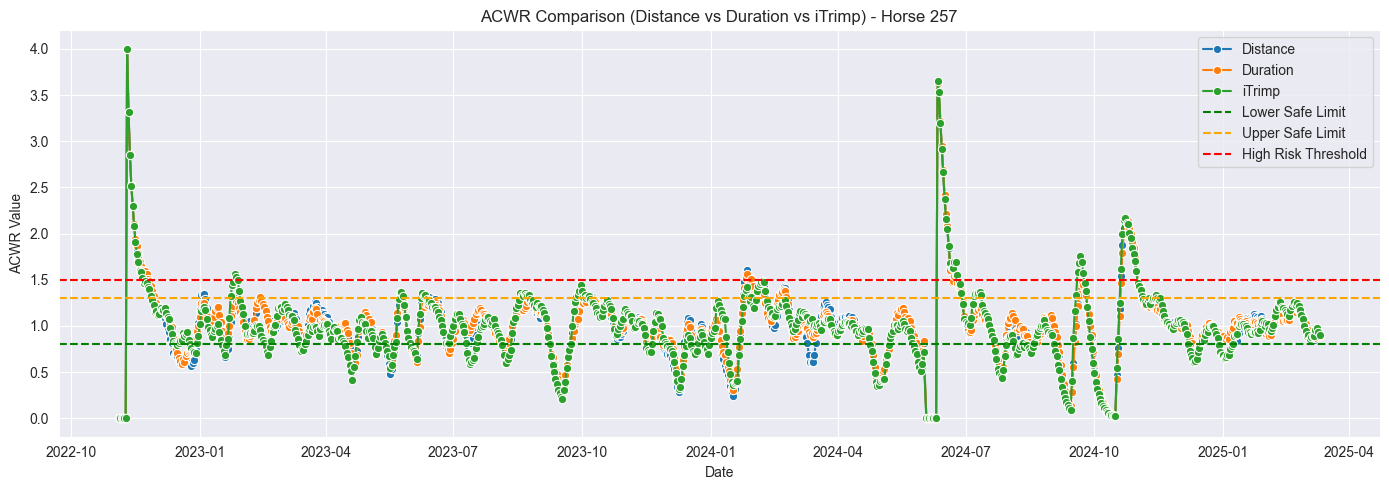

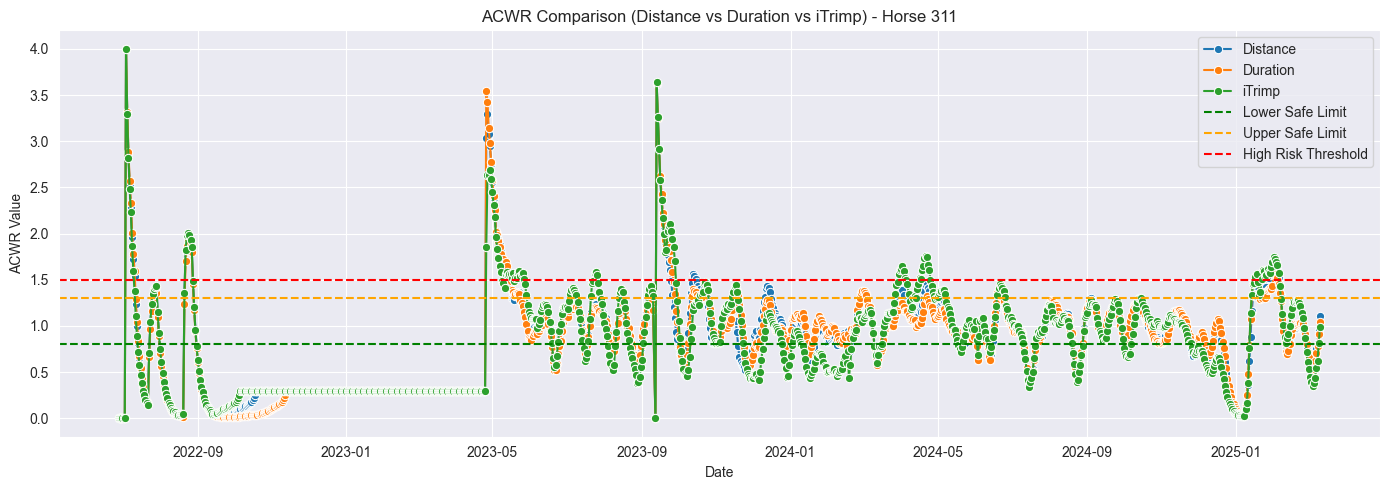

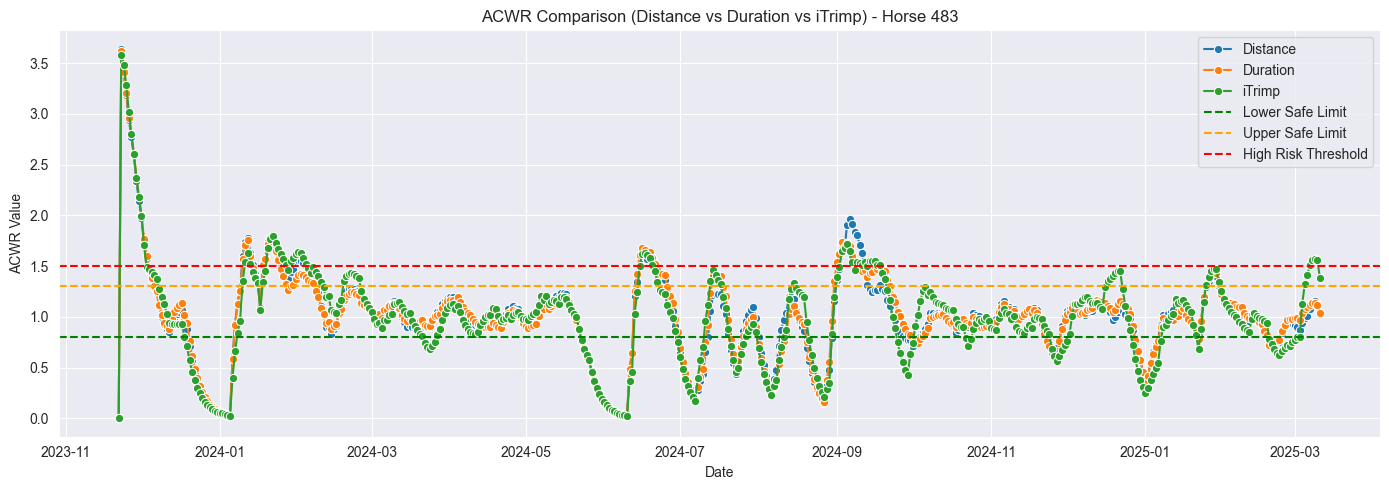

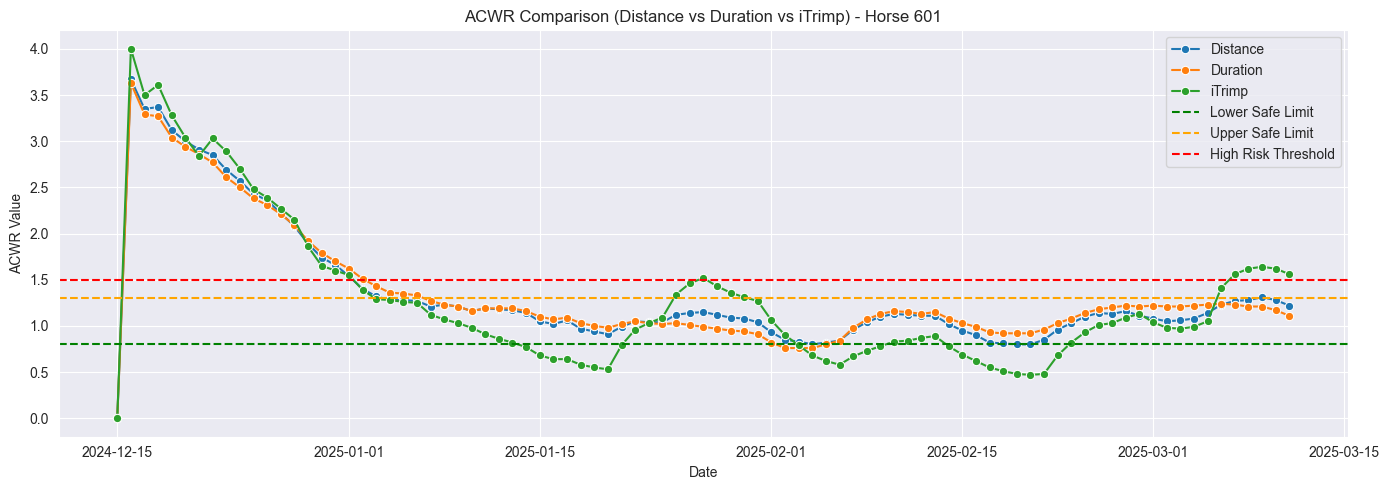

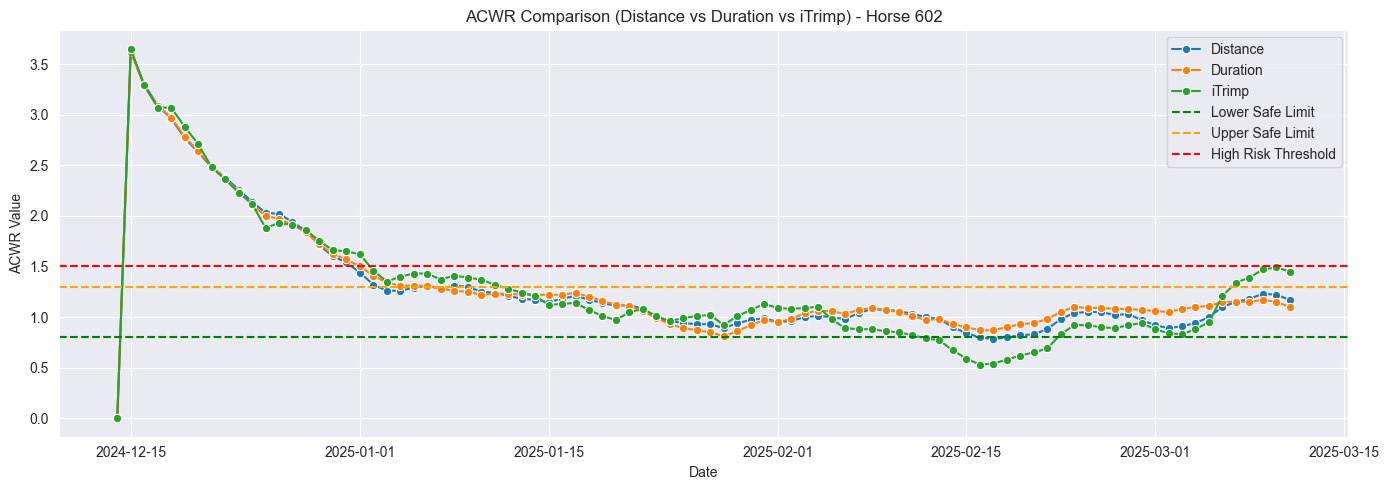

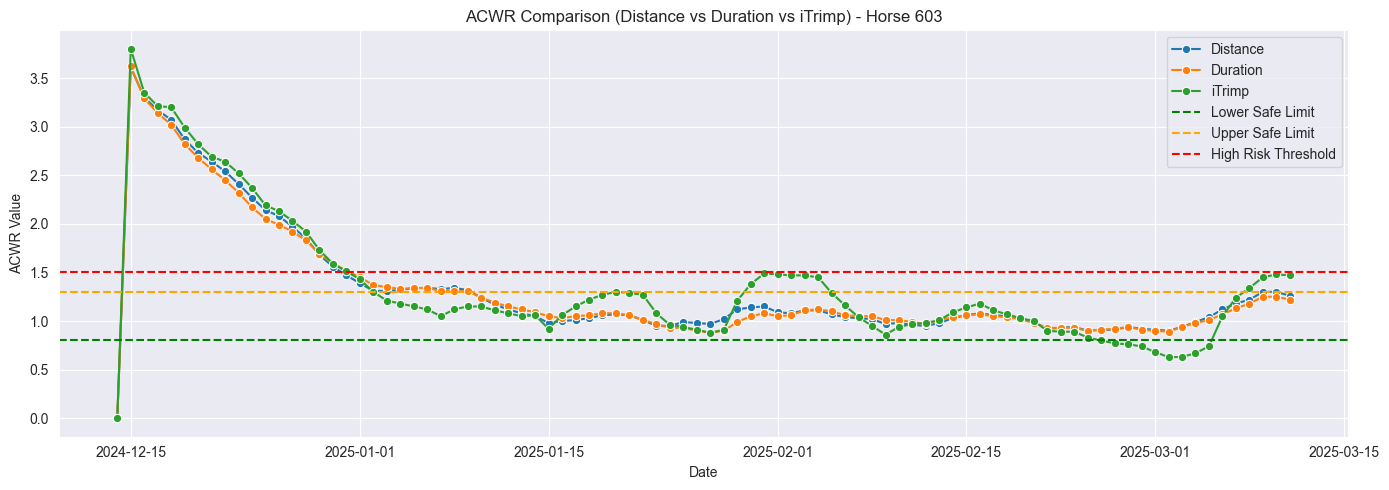

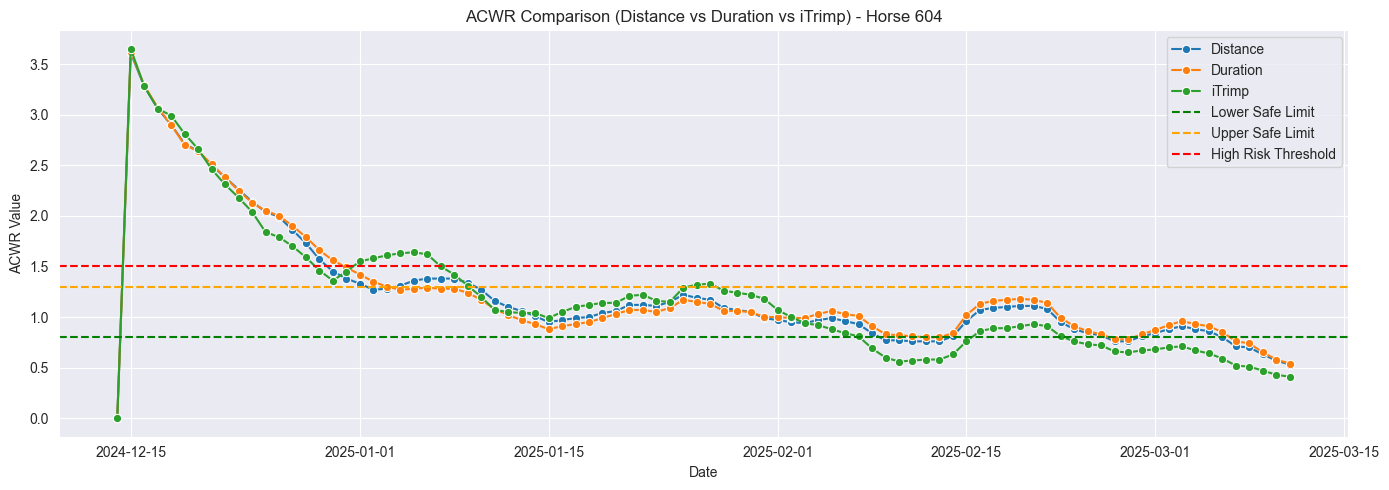

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define the 3 ACWR metric columns
acwr_cols = {
    'Distance': 'externalDistance_Distance_ACWR',
    'Duration': 'externalDuration_Duration_ACWR',
    'iTrimp': 'iTrimp_overall_ACWR'
}

# Prepare data: keep only relevant columns
acwr_df = df[['HorseID', 'Date'] + list(acwr_cols.values())].dropna()

# Convert to float
for col in acwr_cols.values():
    acwr_df[col] = acwr_df[col].astype(float)

# Melt to long format for seaborn
df_melted = acwr_df.melt(id_vars=['HorseID', 'Date'], 
                         value_vars=acwr_cols.values(), 
                         var_name='ACWR_Type', 
                         value_name='ACWR_Value')

# Optional: map technical column names to readable ones
df_melted['ACWR_Type'] = df_melted['ACWR_Type'].map({
    'externalDistance_Distance_ACWR': 'Distance',
    'externalDuration_Duration_ACWR': 'Duration',
    'iTrimp_overall_ACWR': 'iTrimp'
})

# Get unique horses
horses = df_melted['HorseID'].unique()

# Plot all three metrics for each horse
for horse_id in horses:
    horse_df = df_melted[df_melted['HorseID'] == horse_id]

    plt.figure(figsize=(14, 5))
    sns.lineplot(data=horse_df, x='Date', y='ACWR_Value', hue='ACWR_Type', marker='o')
     
    # Thresholds
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold')

    plt.title(f'ACWR Comparison (Distance vs Duration vs iTrimp) - Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR Value')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


After analysis we can see that `Duration` and `Distance` correlate to each other and follow the same pattern for each horse. `ITrimp` however does seem to fluctuate around but still keep the trending of the training exercises which give us conclusion that `Itrimp` might be the best metric to focus on since it represent how horse feels during those exercises and that is what we need to know.

## Data cleaning
Thanks to our client we go to realize that the weird spike up at the beggining of each horse measurement is just how ACWR imbalance calculations since it comare everything to previous weeks which were. To prevent this we are going to drop the first 4 weeks for every horse, since they are not correct data.

In [8]:
one_month_cutoff = df.groupby('HorseID')["Date"].transform(
    lambda s: s.min() + pd.DateOffset(months=1)   # earliest date + 1 month
)

df_clean = df[df["Date"] >= one_month_cutoff].copy()

df_clean.head(2)

,HorseID,Date,externalDistance_Distance_Load_Today,externalDistance_Distance_sevenDay_Total,externalDistance_Distance_AW,externalDistance_Distance_CW,externalDistance_Distance_ACWR,externalDistance_Walk_Distance_Load_Today,externalDistance_Walk_Distance_sevenDay_Total,externalDistance_Walk_Distance_AW,...,iTrimp_canter_Load_Today,iTrimp_canter_sevenDay_Total,iTrimp_canter_AW,iTrimp_canter_CW,iTrimp_canter_ACWR,iTrimp_galop_Load_Today,iTrimp_galop_sevenDay_Total,iTrimp_galop_AW,iTrimp_galop_CW,iTrimp_galop_ACWR
30,257,2022-12-04,7.02,38.37,35.25,30.47,1.16,1.0,9.72,9.80,...,6.37,15.06,10.45,9.57,1.09,0.0,0.0,0.0,0.0,0.0
31,257,2022-12-05,0.00,31.71,34.37,30.56,1.12,0.0,8.30,9.43,...,0.00,12.41,10.94,9.77,1.12,0.0,0.0,0.0,0.0,0.0


### One Plot for each horse

This plot showcases `ITrimp` of each horse after data cleaning. 

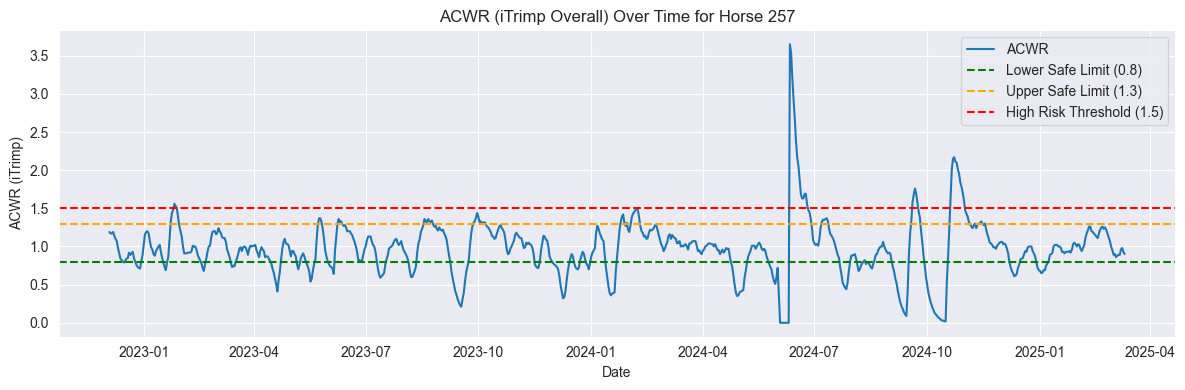

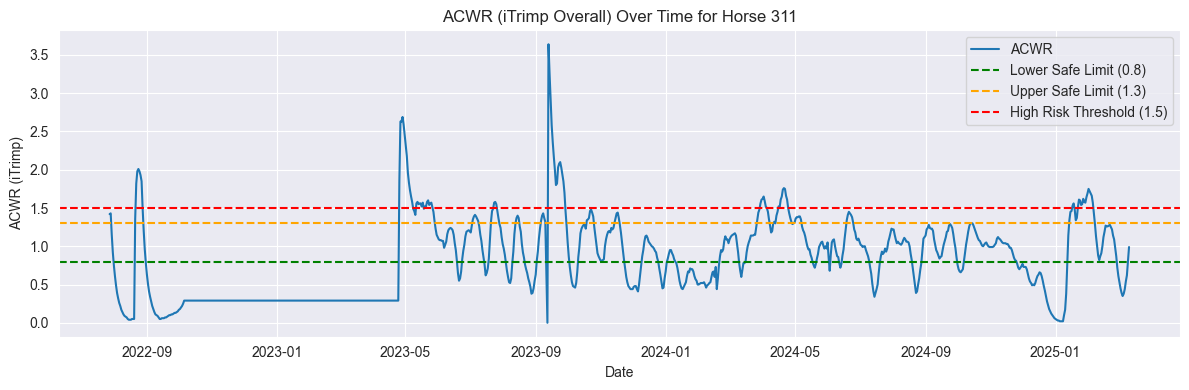

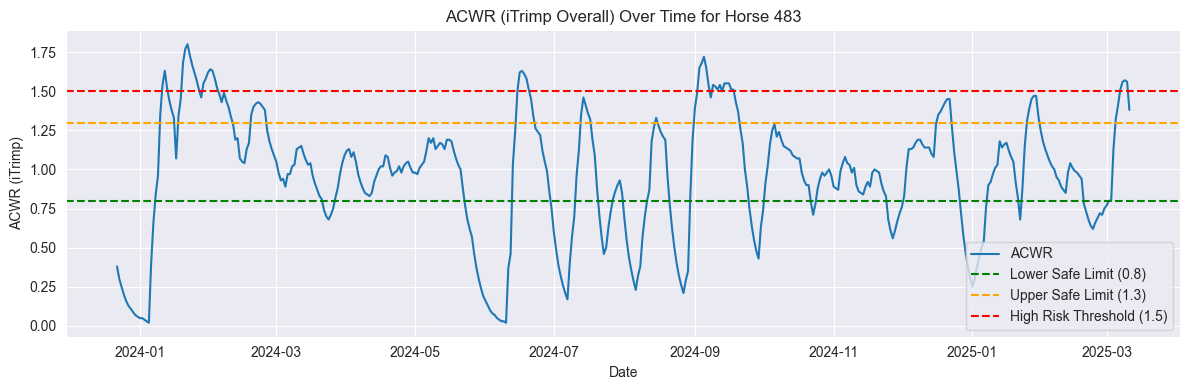

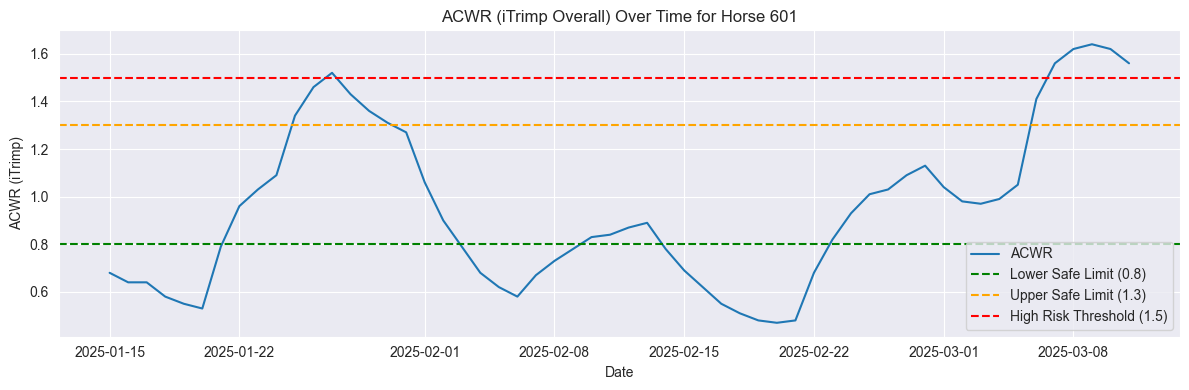

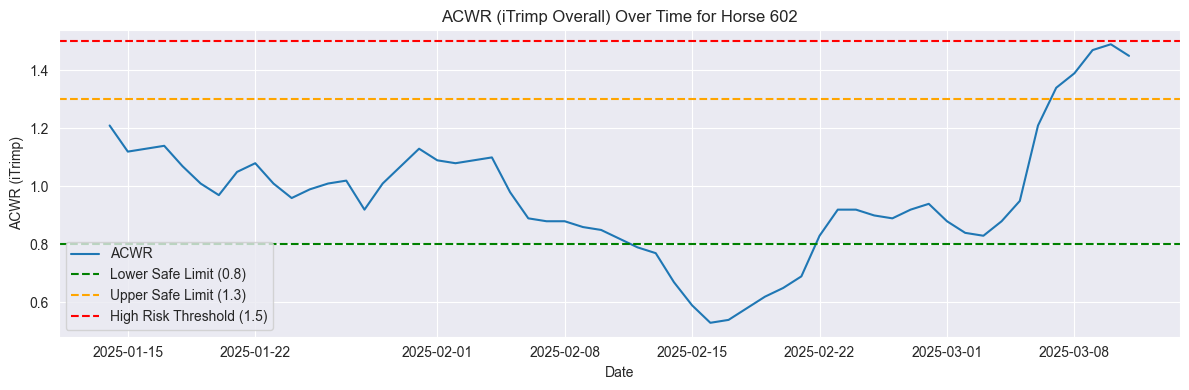

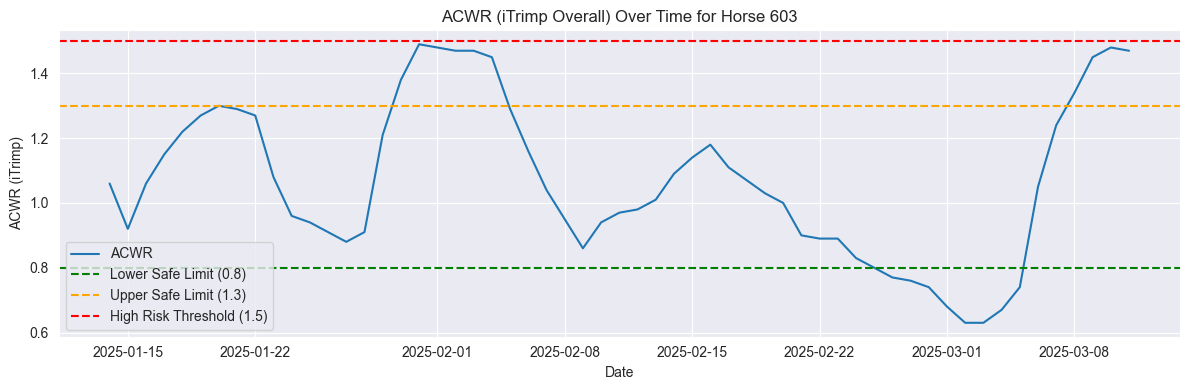

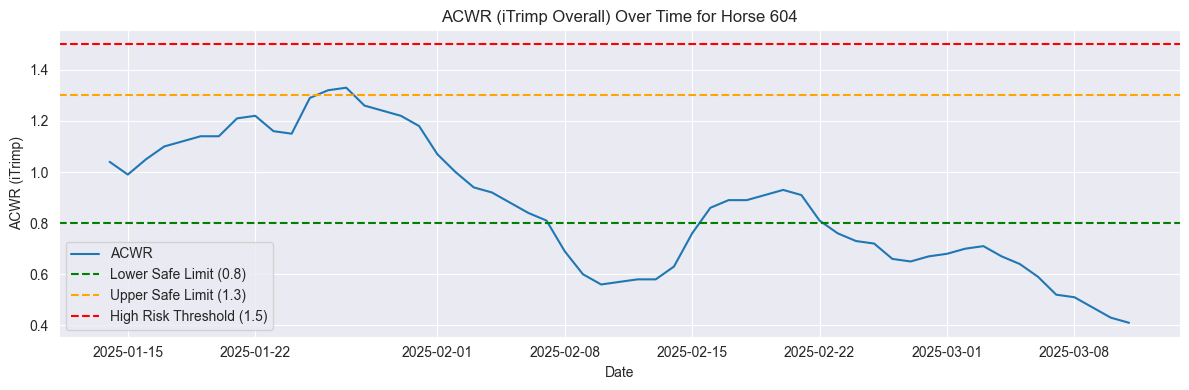

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ACWR metric for internal training load
acwr_col = 'iTrimp_overall_ACWR'

# Filter and clean
df_acwr = df_clean[['HorseID', 'Date', acwr_col]].dropna()
df_acwr[acwr_col] = df_acwr[acwr_col].astype(float)

# Optional: tag risk levels
df_acwr['ACWR_Risk'] = pd.cut(
    df_acwr[acwr_col],
    bins=[-float('inf'), 0.8, 1.3, 1.5, float('inf')],
    labels=['Undertraining', 'Optimal', 'Overreaching', 'Overtraining']
)

# Plot for each horse
horses = df_acwr['HorseID'].unique()

for horse_id in horses:
    horse_df = df_acwr[df_acwr['HorseID'] == horse_id]

    plt.figure(figsize=(12, 4))
    sns.lineplot(data=horse_df, x='Date', y=acwr_col, label='ACWR')
    
    # ACWR safe zone lines
    plt.axhline(0.8, color='green', linestyle='--', label='Lower Safe Limit (0.8)')
    plt.axhline(1.3, color='orange', linestyle='--', label='Upper Safe Limit (1.3)')
    plt.axhline(1.5, color='red', linestyle='--', label='High Risk Threshold (1.5)')
    
    plt.title(f'ACWR (iTrimp Overall) Over Time for Horse {horse_id}')
    plt.xlabel('Date')
    plt.ylabel('ACWR (iTrimp)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Generating Feedback with the Ollama Model

In this section, a large language model (LLM) is used to generate professional feedback for horse trainers based on recent ACWR (Acute:Chronic Workload Ratio) summaries. The approach involves:

- Summarizing the latest ACWR metrics and trends for a selected horse.
- Sending this summary as a prompt to the Ollama model (using the Mistral LLM) via a local command-line interface.
- Automatically generating a concise, expert-level feedback message tailored to the horse's recent workload and risk profile.


In [10]:
horse_id = "601"  # choose one horse
df_horse = df_clean[df_clean["HorseID"] == horse_id].copy()

# Define relevant columns
columns_to_include = [
    "Date",

    # Load_Today
    "iTrimp_overall_Load_Today",
    "iTrimp_walk_Load_Today",
    "iTrimp_trot_Load_Today",
    "iTrimp_canter_Load_Today",
    "iTrimp_galop_Load_Today",

    # ACWR
    "iTrimp_overall_ACWR",
    "iTrimp_walk_ACWR",
    "iTrimp_trot_ACWR",
    "iTrimp_canter_ACWR",
    "iTrimp_galop_ACWR",
]

# Filter out rows with missing values in any of those columns
df_horse = df_horse[columns_to_include].dropna()

# Convert ACWR columns to float (if needed)
acwr_columns = [col for col in columns_to_include if "ACWR" in col]
df_horse[acwr_columns] = df_horse[acwr_columns].astype(float)

df_horse.head(3)


,Date,iTrimp_overall_Load_Today,iTrimp_walk_Load_Today,iTrimp_trot_Load_Today,iTrimp_canter_Load_Today,iTrimp_galop_Load_Today,iTrimp_overall_ACWR,iTrimp_walk_ACWR,iTrimp_trot_ACWR,iTrimp_canter_ACWR,iTrimp_galop_ACWR
2352,2025-01-15,0.0,0.0,0.00,0.00,0.0,0.68,0.78,0.67,1.38,0.43
2353,2025-01-16,4.09,2.48,1.37,0.14,0.0,0.64,0.84,0.63,1.20,0.35
2354,2025-01-17,1.72,0.31,2.60,0.03,0.0,0.64,0.89,0.63,1.08,0.28


In [11]:
import subprocess
import json

def generate_local_feedback(summary_text):
    prompt = f"""
You are an equine sports scientist. Based on the horse's training data, write a short and helpful feedback message for the trainer. Use a professional and supportive tone.

The data includes:
- Date
- Training Load (Load)
- ACWR (Acute:Chronic Workload Ratio)
- Zone (training quality: undertrained, optimal, overtrained)

Guidelines:
- Comment on the overall training balance.
- Point out gaits that are undertrained or overtrained (based on Zone).
- Note that some days have Load = 0 (recovery days).
- Give clear advice on adjusting training or giving rest.

Provide only the feedback with explanations. No summaries.


--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Trainer Feedback:
"""
    
    # Send to Ollama (CLI mode)
    result = subprocess.run(
        ['ollama', 'run', 'mistral'],
        input=prompt.encode(),
        stdout=subprocess.PIPE
    )

    output = result.stdout.decode('utf-8')
    return output.strip()



In [12]:
from datetime import timedelta

def get_risk_zone(acwr):
    if acwr < 0.8:
        return "Undertrained"
    elif acwr > 1.5:
        return "Overtrained"
    else:
        return "Optimal"

def summarize_recent_7_days(df_horse):
    df_recent = df_horse.sort_values("Date").tail(7)
    summary = "Recent 7 Days Training Summary:\n"

    for _, row in df_recent.iterrows():
        summary += f"{row['Date'].strftime('%Y-%m-%d')}:\n"
        for gait in ["walk", "trot", "canter", "galop"]:
            load = row[f"iTrimp_{gait}_Load_Today"]
            acwr = row[f"iTrimp_{gait}_ACWR"]
            zone = get_risk_zone(acwr) if load > 0 else "Not Trained"
            summary += f"  {gait.capitalize()} - Load: {load:.1f} | ACWR: {acwr:.2f} | Zone: {zone}\n"
    return summary

def summarize_weekly_averages(df_horse):
    df_sorted = df_horse.sort_values("Date")
    df_sorted['Week'] = df_sorted['Date'].dt.to_period('W').apply(lambda r: r.start_time)

    weeks = sorted(df_sorted['Week'].unique())[-6:-1]  # Previous 5 full weeks

    summary = "\nPrevious 5 Weeks Overview:\n"

    for week_start in weeks:
        week_data = df_sorted[df_sorted['Week'] == week_start]
        if len(week_data) == 0:
            continue
        avg_load = week_data["iTrimp_overall_Load_Today"].mean()
        avg_acwr = week_data["iTrimp_overall_ACWR"].mean()
        zone = get_risk_zone(avg_acwr)
        week_end = week_start + timedelta(days=6)
        summary += f"Week ({week_start.date()} to {week_end.date()}): Avg Load: {avg_load:.1f} | Avg ACWR: {avg_acwr:.2f} | Zone: {zone}\n"
    return summary

# Make sure Date column is datetime
df_horse["Date"] = pd.to_datetime(df_horse["Date"])

# Generate the summary text
summary_text = summarize_recent_7_days(df_horse) + "\n" + summarize_weekly_averages(df_horse)
print(summary_text)


Recent 7 Days Training Summary:
2025-03-05:
  Walk - Load: 0.4 | ACWR: 0.91 | Zone: Optimal
  Trot - Load: 4.5 | ACWR: 1.33 | Zone: Optimal
  Canter - Load: 0.1 | ACWR: 1.08 | Zone: Optimal
  Galop - Load: 0.0 | ACWR: 0.39 | Zone: Not Trained
2025-03-06:
  Walk - Load: 3.2 | ACWR: 1.06 | Zone: Optimal
  Trot - Load: 11.7 | ACWR: 1.51 | Zone: Overtrained
  Canter - Load: 0.0 | ACWR: 1.21 | Zone: Not Trained
  Galop - Load: 102.4 | ACWR: 1.07 | Zone: Optimal
2025-03-07:
  Walk - Load: 0.0 | ACWR: 1.16 | Zone: Not Trained
  Trot - Load: 0.0 | ACWR: 1.59 | Zone: Not Trained
  Canter - Load: 0.0 | ACWR: 1.28 | Zone: Not Trained
  Galop - Load: 0.0 | ACWR: 1.41 | Zone: Not Trained
2025-03-08:
  Walk - Load: 0.2 | ACWR: 1.19 | Zone: Optimal
  Trot - Load: 2.4 | ACWR: 1.62 | Zone: Overtrained
  Canter - Load: 0.0 | ACWR: 1.28 | Zone: Not Trained
  Galop - Load: 0.0 | ACWR: 1.57 | Zone: Not Trained
2025-03-09:
  Walk - Load: 0.4 | ACWR: 1.22 | Zone: Optimal
  Trot - Load: 0.6 | ACWR: 1.62 | Zon

This is a summary of the input that is send to the our model. We decided to stick to simple data of putting Load and ACWR for current week and ACWR averages of previous weeks for model to compare. We also noticed that with increased data the time also increases for model to genere the feedback so depends on the computers GPU it might take either below 2 minutes or even over 5 minutes.

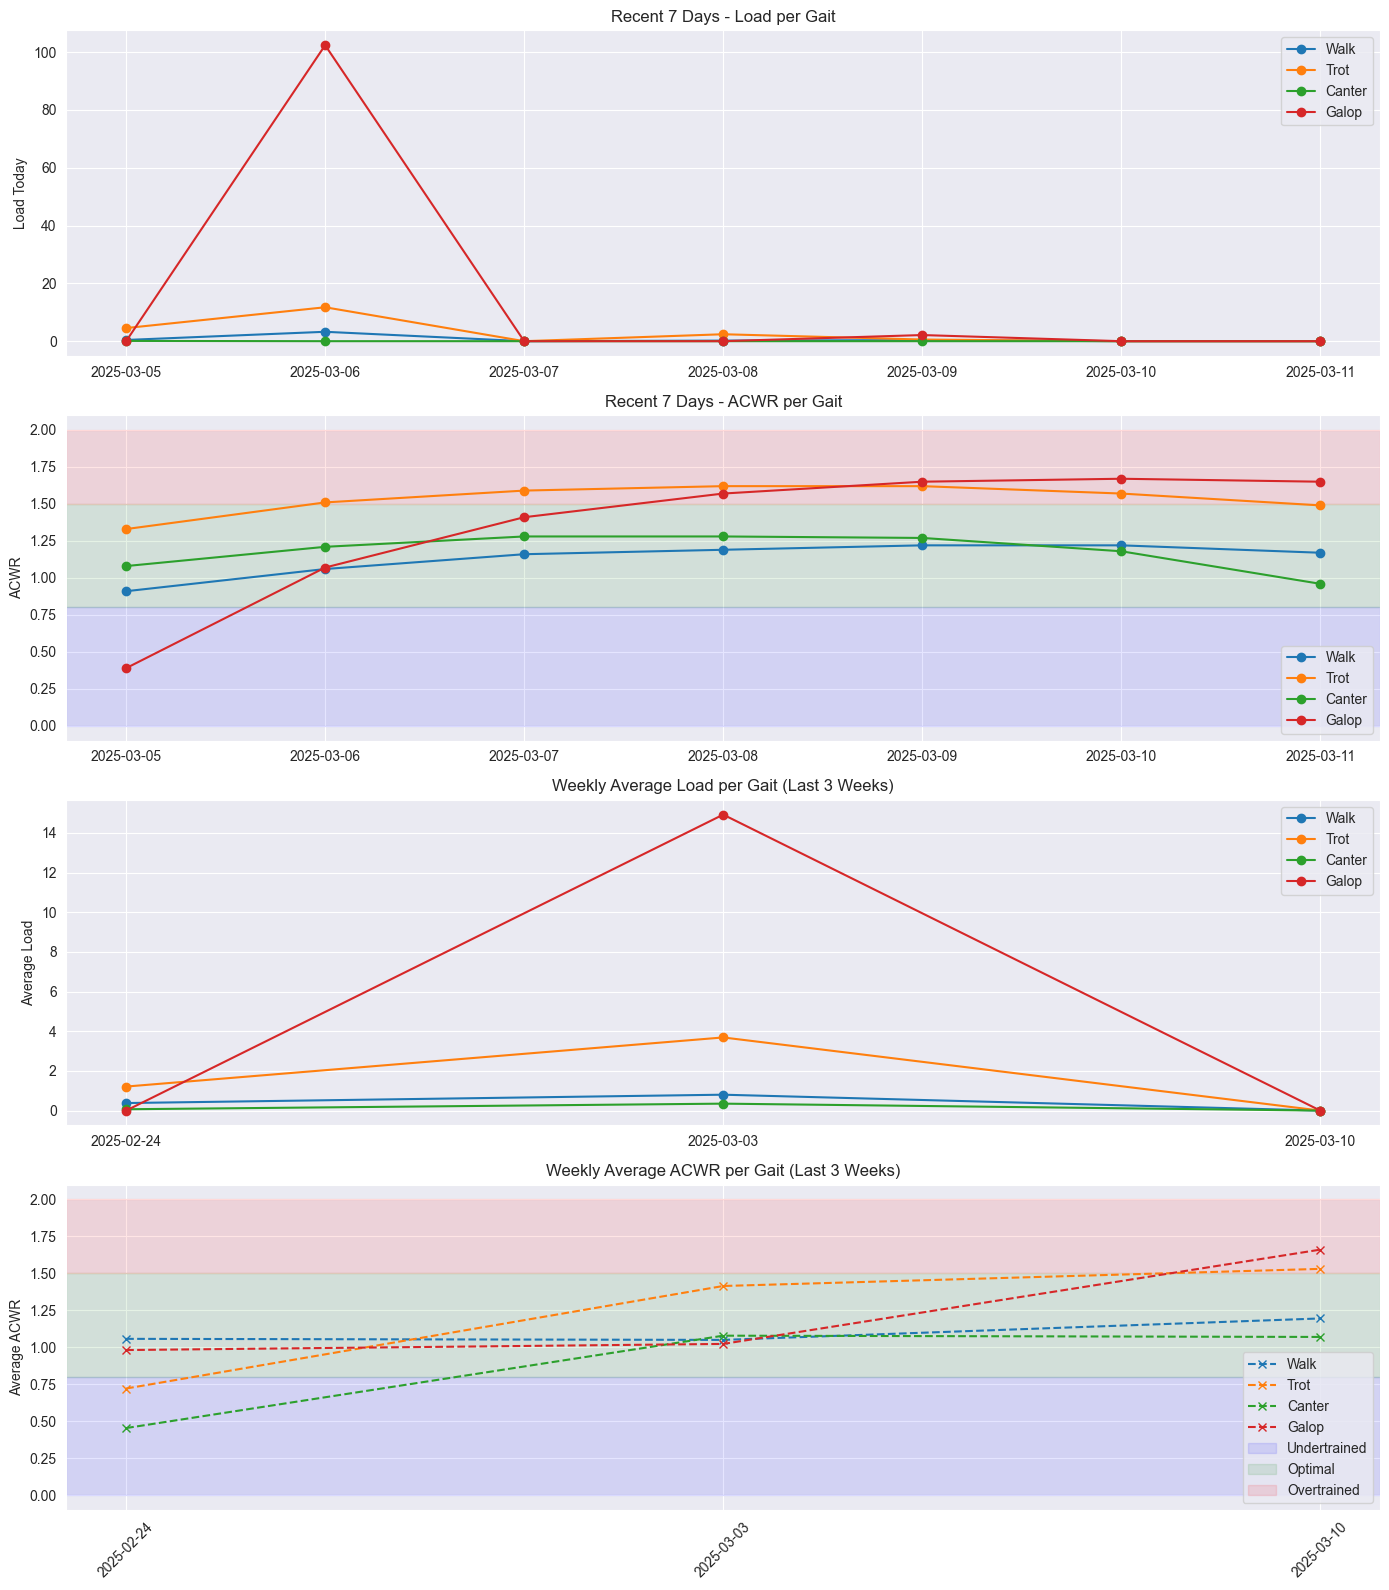

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_training_summary(df_horse):
    df_horse = df_horse.sort_values("Date")
    gaits = ["walk", "trot", "canter", "galop"]
    
    # --- PREPARE DATA ---
    df_recent = df_horse.tail(7)
    dates = df_recent["Date"].dt.strftime("%Y-%m-%d")

    df_horse["Week"] = df_horse["Date"].dt.to_period("W").apply(lambda r: r.start_time)
    last_3_weeks = df_horse["Week"].dropna().unique()[-3:]
    df_weekly = df_horse[df_horse["Week"].isin(last_3_weeks)]

    weekly_agg = df_weekly.groupby("Week").agg({
        **{f"iTrimp_{g}_Load_Today": 'mean' for g in gaits},
        **{f"iTrimp_{g}_ACWR": 'mean' for g in gaits}
    }).reset_index()
    weeks = weekly_agg["Week"].dt.strftime('%Y-%m-%d')

    # --- PLOTS ---
    fig, axs = plt.subplots(4, 1, figsize=(14, 16), sharex=False)

    # 1. Daily Load (7 days)
    for gait in gaits:
        axs[0].plot(dates, df_recent[f"iTrimp_{gait}_Load_Today"], marker='o', label=gait.capitalize())
    axs[0].set_ylabel("Load Today")
    axs[0].set_title("Recent 7 Days - Load per Gait")
    axs[0].legend()
    axs[0].grid(True)

    # 2. Daily ACWR (7 days)
    for gait in gaits:
        axs[1].plot(dates, df_recent[f"iTrimp_{gait}_ACWR"], marker='o', label=gait.capitalize())
    axs[1].axhspan(0, 0.8, color='blue', alpha=0.1)
    axs[1].axhspan(0.8, 1.5, color='green', alpha=0.1)
    axs[1].axhspan(1.5, 2.0, color='red', alpha=0.1)
    axs[1].set_ylabel("ACWR")
    axs[1].set_title("Recent 7 Days - ACWR per Gait")
    axs[1].legend()
    axs[1].grid(True)

    # 3. Weekly Average Load
    for gait in gaits:
        axs[2].plot(weeks, weekly_agg[f"iTrimp_{gait}_Load_Today"], marker='o', label=gait.capitalize())
    axs[2].set_title("Weekly Average Load per Gait (Last 3 Weeks)")
    axs[2].set_ylabel("Average Load")
    axs[2].legend()
    axs[2].grid(True)

    # 4. Weekly Average ACWR
    for gait in gaits:
        axs[3].plot(weeks, weekly_agg[f"iTrimp_{gait}_ACWR"], marker='x', linestyle='--', label=gait.capitalize())
    axs[3].axhspan(0, 0.8, color='blue', alpha=0.1, label='Undertrained')
    axs[3].axhspan(0.8, 1.5, color='green', alpha=0.1, label='Optimal')
    axs[3].axhspan(1.5, 2.0, color='red', alpha=0.1, label='Overtrained')
    axs[3].set_title("Weekly Average ACWR per Gait (Last 3 Weeks)")
    axs[3].set_ylabel("Average ACWR")
    axs[3].legend()
    axs[3].grid(True)
    axs[3].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

plot_training_summary(df_horse)

Here is also graphical representation of the inputed data for `Load` and `ACWR`.

In [14]:
# Pass to Mistral model for feedback
feedback = generate_local_feedback(summary_text)
print("\nFeedback for trainer:")
print(feedback)



Feedback for trainer:
Dear Trainer,

I hope this message finds you well. I've analyzed the training data for your equine athlete over the past week and compared it with the previous five weeks for a comprehensive overview. Here are my insights:

In the past seven days, the horse has been performing at optimal levels during walks, trots, and canters based on the Acute:Chronic Workload Ratio (ACWR). However, there seems to be an overtraining pattern emerging in the Galop gait during these days. The high loads and ACWR values indicate that the horse is being pushed beyond its current training capacity, which may lead to potential injuries or fatigue if not addressed promptly.

It's essential to remember that some days were set aside for recovery (Load = 0), which helps maintain a balanced training program. However, it appears that the rest periods might have been insufficient in recent days due to high workloads on other days.

Looking at the longer-term trend, the horse has been consist


###  **Conclusion: Personalized Equine Training Feedback System**

In this project, we developed a data-driven approach to **analyze horse training patterns** and generate **personalized, expert-level feedback** for trainers. The core objective was to ensure each horse's workload is optimized for health and performance, using **ACWR (Acute\:Chronic Workload Ratio)** and daily training loads across different gaits (walk, trot, canter, galop).

####  Key Steps in the Process:

1. **Data Selection & Filtering**
   We isolated training data for individual horses and ensured only complete, valid rows were used for analysis.

2. **Metric Summarization**
   For the **recent 7 days**, we created summaries that included daily load, ACWR, and risk zones to assess training adequacy per gait.

3. **Risk Zone Classification**
   Using scientifically accepted thresholds:

   * ACWR < 0.8 → **Undertrained**
   * 0.8 ≤ ACWR ≤ 1.5 → **Optimal**
   * ACWR > 1.5 → **Overtrained**

4. **Visualizations**
   We enhanced interpretability by plotting **daily load and ACWR trends**, highlighting fluctuations and risk zones clearly for each gait.

5. **Feedback Generation**
   A structured natural language prompt was crafted and passed to a local language model (via Ollama and Mistral), which generated **human-readable, supportive, and actionable feedback** tailored to the horse’s specific data patterns.

####  Benefits of This Approach:

* Offers **objective, evidence-based feedback** for trainers.
* Identifies **undertraining, overtraining, or erratic patterns** early to prevent injuries or performance drops.
* Helps tailor **gait-specific recommendations**.
* Supports **decision-making for rest or load adjustments** with confidence.
* Lays a foundation for **scalable, automated equine performance monitoring**.

---

####  Limitations:

1. **Model Performance & Hardware Dependency**

   * The feedback generation process relies on local large language models (like Mistral via Ollama), which require **significant system resources**, particularly **a strong GPU** for reasonable runtime performance.
   * On lower-end systems, the generation may be **slow or unresponsive**, impacting real-time usability.

2. **Feedback Validity & Scientific Rigor**

   * While the language model provides **expert-style output**, it does **not perform real scientific validation** of the suggestions.
   * The generated feedback may **lack clinical vetting**, and thus should be **reviewed by qualified equine professionals** before implementation.

3. **Limited Context Awareness**

   * The model is **only as good as the input summary** it receives. If the summary lacks context (e.g. competition schedule, medical history), the feedback may miss important nuances.

4. **No Learning or Feedback Loop**

   * The model does **not learn over time** or adapt based on previous feedback accuracy or outcomes. This limits personalization unless explicitly integrated in future iterations.

---


## New prompts and Different models

### Create fucntion

In [15]:
# STEP 1 – Set up local feedback generation using Ollama
import subprocess

def generate_local_feedback(summary_text, model_name, prompt_template):
    prompt = prompt_template.format(summary_text=summary_text)

    result = subprocess.run(
        ["ollama", "run", model_name],
        input=prompt.encode(),
        stdout=subprocess.PIPE
    )

    return result.stdout.decode("utf-8").strip()


### Create a list of models we want to test

In [16]:
# models = ["mistral", "llama3", "gemma:7b", "nous-hermes"]
models = ["gemma:7b"]

### Create a list of Prompts to compare

In [17]:
# Horse 257 – Dutch, example-based style
prompt_horse_257 = """
You are an equine sports scientist. Based on the horse's training data, write a short and helpful feedback message for the trainer. I'm going to give you:
 - An example message, which you should analyze and keep the same writing style and structure
 - Horse Summary Data (listed in chronological order—from oldest to newest)
 - Data explanation
 - Guidelines on what you should give back as answer

Example message:
hierbij de feedback op de laatste trainingen:
18 juni: Galop is nog wat intensiever, maar hij herstelt hier wel redelijk van. Laatste draf blok is wel matig tot hoog intensieve draf werk voor hem. Niet erg voor een keer, maar beter om dit blok op te delen in 2 of 3 kortere blokjes afgewisseld met wat stap.
21 juni: wel intensief dagje, blokjes in de galop zijn wel van hoge intensiteit maar niet meteen verkeerd en ook niet alleen inspanning want herstel erna is redelijk snel en te snel als het alleen maar hoog was van inspanning. Goed dat je korte stukjes hebt gedaan. Stukje proef op einde wel goed, was ook iets hoger intensief, maar dat mag, hij mag er ook aan blijven trekken zeg maar. herstel na de training was snel en goed dus al met al matig intensieve training. Dus denk goede intensiteit en technisch ook goed.
22 juni: prima herstel dagje in het bos.
--- Example message End ---

Horse Summary Data (chronologisch):
{summary_text}
--- Training Summary End ---

Data Explanation:
- Date
- Training Load (Load)
- ACWR (Acute:Chronic Workload Ratio)
- Zone (training quality: undertrained, optimal, overtrained)
--- Data Explanation End ---

Guidelines:
1. **Chronological order**: comment starting with the oldest date, ending with the most recent.
2. **Amplitude of change**: note how much Load or ACWR has risen or fallen compared to the previous day.
3. **Undertrained days**: if Zone = undertrained on any day, explicitly call out “Ondertraind op [date]” and advise how to improve.
4. **Recovery days**: note days with Load = 0 as planned rest.
5. **Overall balance**: summarize the week’s workload balance at the end.
6. **Tone**: write professionally in Dutch, date: feedback per line.

Provide only the feedback with explanations. No summaries or extra sections.
"""

# Horse 311 – Short English feedback, MM-DD format
prompt_horse_311 = """
You are an equine training assistant. Your task is to generate clear, helpful daily feedback for a horse trainer, based on the training summary.

INSTRUCTIONS:
- Write one short feedback line per day (1–2 sentences max).
- Use the **date format MM-DD** exactly as shown in the data (e.g. "03-05:" for March 5).
- Follow the **same order as the summary**, from earliest to most recent.
- DO NOT sort or reverse the dates.
- DO NOT include the year in the date.
- Comment on training intensity (e.g., low/moderate/high), recovery, or any oddities.
- Mention undertrained or overtrained gaits (from the "Zone").
- Give tips or suggestions only if needed (optional).
- DO NOT write any introduction, summary, or extra text.

--- Horse Summary Data ---
{summary_text}
--- End Summary ---

Write your feedback below using this format:
MM-DD: feedback here.
"""

# Horse 483 – Dutch daily feedback, focus on tone
prompt_horse_483 = """
Je bent een paardensporttrainer en schrijft dagelijkse feedback op basis van de trainingsdata van een paard.

Werkwijze:
- Lees de datums direct uit de trainingsdata hieronder (formaat: YYYY-MM-DD).
- Zet elke feedbackregel in de vorm: **MM-DD: feedback** (dus alleen maand en dag, géén jaartal).
- Gebruik de exacte **volgorde van de datums zoals ze voorkomen in de data** (van vroeger naar recenter).
- Schrijf maximaal 1–2 zinnen per datum.

Inhoud van elke feedback:
- Geef de intensiteit van de training aan (bijv. laag, licht-matig, matig, intensief).
- Benoem opvallend gedrag, herstel, of hartslag.
- Voeg indien zinvol een praktische suggestie toe (bijv. hoe vaak een oefening herhaald mag worden).
- **Let op:** een lage ACWR-waarde is niet altijd slecht — dit kan duiden op een geplande rustperiode, vooral als het paard eerder overtraind was of intensief getraind heeft. Interpreteer ACWR dus in context van de voorgaande dagen.
- Gebruik een vriendelijke, persoonlijke en deskundige toon.
- Schrijf **alleen** de feedbackregels — géén inleidingen of samenvattingen.

--- Trainingsdata ---
{summary_text}
--- Einde Trainingsdata ---

Schrijf nu de feedback per dag in dit formaat:
MM-DD: feedback hier.
"""

# Horse 601 – Long expert feedback, with planning
prompt_horse_601 = """
You are a horse sport trainer writing personalized training feedback for a horse based on detailed tracking data.

Objective:
Give **clear, detailed feedback** for each day, in a supportive, expert tone. Feedback may include **observations, suggestions, and planning** advice.

Instructions:
- Extract dates from the data (format: YYYY-MM-DD).
- Write feedback lines in **MM-DD format only**, like “01-05:”.
- Follow the **exact order as in the data** (oldest to newest).
- Write 1–3 sentences per date if needed — longer feedback is allowed when needed for explanation.
- Mention the **specific gaits** (walk, trot, canter, galop) and relevant data per gait (e.g., HR, recovery).
- Include **contextual interpretation** (e.g., Sleip data, farrier, lesson, rider impression, hill work).
- Give **planning advice** where useful (e.g., what to do next session, how to taper before events).
- Use natural trainer tone — like someone writing to a rider they know well.
- **Low ACWR is not necessarily bad** — may reflect intentional rest. Interpret in context of the training pattern.
- Do **not** include summaries, conclusions, or any introduction — only feedback per day.

--- Training Data ---
{summary_text}
--- End of Data ---

Write your feedback below like this:
MM-DD: your feedback.
"""

# Horse 602 – Concise technical coach notes
prompt_horse_602 = """
You are an experienced equine performance coach. Based on the horse's training data, write a concise, date-by-date feedback message for the trainer—in English only.

The data includes:
- Date
- Training Load (Load)
- ACWR (Acute:Chronic Workload Ratio)
- Zone (training quality: undertrained, optimal, overtrained)

Guidelines:
1. List each day **chronologically** (oldest → newest), one line per date, in the format:
   15 Dec: feedback…
   17 Dec: feedback…
2. Tone: friendly yet professional (“nice low-intensity recovery day”, “well done!”, “keep it up!”).
3. Content for each line:
   - Session type (flat work, dressage, conditioning, swim gym, etc.)
   - Intensity (low, moderate, high); if Load = 0, call it a “recovery day”
   - Recovery observations (“heart rate returned to baseline quickly”)
   - Any asymmetries or balance issues (“slightly weaker on right hind”; “work on left lead”)
   - A brief technical tip or next focus (“add poles for engagement”; “practice uphill transitions”)

--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Provide **only** the feedback lines in English, formatted as shown above.
"""

# Horse 603 – Interpreted conditioning notes
prompt_horse_603 = """
You are an experienced equine performance coach. Based on the horse's training data, write a concise, date-by-date feedback message for the trainer—in English only.

The data includes:
- Date
- Training notes

Guidelines:
1. List each day chronologically (oldest → newest), one line per date, in the format:
   15 Dec: feedback…
   17 Dec: feedback…
2. Tone: friendly yet professional (“nice low-intensity recovery day”, “well done!”, “keep it up!”).
3. For each line include:
   - Session type (flat work, dressage, conditioning, swim gym, etc.)
   - Intensity (low, moderate, high); if truly a “recovery day” call it that
   - Recovery observations (“heart rate returned to baseline quickly”)
   - Any minor asymmetries (“slightly weaker on right hind”; “work on left lead”)
   - A brief technical tip or next focus (“add poles for engagement”; “practice uphill transitions”)

--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Provide only the feedback lines in English, formatted as shown above.
"""

# Horse 604 – Sleip monitoring and workload guidance
prompt_horse_604 = """
You are an experienced equine performance coach. Based on the horse's training data, write a concise, date-by-date feedback message for the trainer—in English only.

The data includes simple daily notes.

Guidelines:
1. List each day chronologically (oldest → newest), one line per date, in the format:
   15 Dec: feedback…
   17 Dec: feedback…
2. Tone: friendly yet professional (“nice low-intensity recovery day”, “well done!”, “keep it up!”).
3. For each line include:
   - Session type (flat work, dressage, conditioning, swim gym, etc.)
   - Intensity (low, moderate, high); if recovery call it a “recovery day”
   - Recovery observation (“heart rate returned to baseline quickly”)
   - Any minor asymmetries (“slightly weaker on right hind”; “work on left lead”)
   - A brief technical tip or next focus (“add poles for engagement”; “practice uphill transitions”)

--- Training Summary Start ---
{summary_text}
--- Training Summary End ---

Provide only the feedback lines in English, one per date.
"""


### Compare models

In [19]:
# STEP 3 — Select specific horse and prompt to run

# Select model
models = ["gemma"]  # or ["mistral"], etc.

# Select horse
horse_name = "Horse 257"  # replace this when running too
summary_text_input = summary_text  # replace with summary_text_XXX for other horses
prompt = prompt_horse_257          # replace with any other prompt_xxx

# Run model(s)
comparison_results = {}

for model_name in models:
    print(f"\n>>> Running {model_name} on {horse_name}…")

    feedback = generate_local_feedback(summary_text_input, model_name, prompt)
    comparison_results[(model_name, horse_name)] = feedback

# Print result
for (model_name, horse_name), feedback in comparison_results.items():
    print(f"\n\n============================")
    print(f"MODEL: {model_name.upper()} | {horse_name}")
    print("============================\n")
    print(feedback)



>>> Running gemma on Horse 257…


MODEL: GEMMA | Horse 257

03-05: Good walk engagement with low load. Maintain optimal trot and canter zones. 
03-06: High trot load suggests overtraining. Consider reducing workload. 
03-07: Focus on walk and canter development. 
03-08: Moderate trot load, but maintain optimal canter zone. 
03-09: Continue addressing trot overtraining. 
03-10: Maintain walk and canter development. 
03-11: Excellent canter engagement with low load.
